In [1]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_ollama import ChatOllama
from dotenv import load_dotenv

In [2]:
load_dotenv()

False

In [3]:
class ParentState(TypedDict):

    question: str
    answer_eng: str
    answer_hin: str

In [4]:
parent_llm = ChatOllama(
    model="llama3.2:1b",
    temperature=0
)
subgraph_llm = ChatOllama(
    model="llama3.2:1b",
    temperature=0
)

In [5]:
def translate_text(state: ParentState):

    prompt = f"""
Translate the following text to Hindi.
Keep it natural and clear. Do not add extra content.

Text:
{state["answer_eng"]}
""".strip()
    
    translated_text = subgraph_llm.invoke(prompt).content

    return {'answer_hin': translated_text}

In [6]:
subgraph_builder = StateGraph(ParentState)

subgraph_builder.add_node('translate_text', translate_text)

subgraph_builder.add_edge(START, 'translate_text')
subgraph_builder.add_edge('translate_text', END)

subgraph = subgraph_builder.compile()

In [7]:
def generate_answer(state: ParentState):

    answer = parent_llm.invoke(f"You are a helpful assistant. Answer clearly.\n\nQuestion: {state['question']}").content
    return {'answer_eng': answer}

In [8]:
parent_builder = StateGraph(ParentState)

parent_builder.add_node("answer", generate_answer)
parent_builder.add_node("translate", subgraph)

parent_builder.add_edge(START, 'answer')
parent_builder.add_edge('answer', 'translate')
parent_builder.add_edge('translate', END)

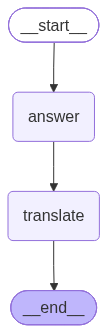

In [9]:
graph = parent_builder.compile()

graph

In [10]:
graph.invoke({'question': 'What is quantum physics'})

{'question': 'What is quantum physics',
 'answer_eng': "Quantum physics, also known as quantum mechanics, is a branch of physics that studies the behavior of matter and energy at an atomic and subatomic level. It's a complex and fascinating field that has revolutionized our understanding of the natural world.\n\nIn simple terms, quantum physics explains how tiny particles like atoms, electrons, and photons (particles of light) behave and interact with each other. At these scales, the usual rules of classical physics don't apply, and strange, seemingly random phenomena occur.\n\nSome key features of quantum physics include:\n\n1. **Wave-particle duality**: Tiny particles can exhibit both wave-like and particle-like behavior, depending on how they're observed.\n2. **Uncertainty principle**: It's impossible to know certain properties of a particle, like position and momentum, simultaneously with infinite precision.\n3. **Superposition**: Particles can exist in multiple states simultaneous